## Use SHAP values to interpret model predictions by manually computing Shapley values, visualizing their impact on individual predictions without using built-in SHAP libraries, and analyzing feature contribution variability.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

df = pd.read_csv('heart.csv')                         
feat = [c for c in df.columns if c != 'target']; n = len(feat)
X, y = df[feat].values.astype(float), df['target'].values
idx = np.random.default_rng(0).permutation(len(X)); cut = int(0.8 * len(X)); tr, te = idx[:cut], idx[cut:]

rf = RandomForestClassifier(100, max_depth=5, min_samples_leaf=3, random_state=0).fit(X[tr], y[tr])
f = lambda A: rf.predict_proba(A)[:, 1]               # model = P(disease)
print('Test accuracy:', np.mean((f(X[te]) > 0.5) == y[te]).round(3), '| features:', n)

bg = X[tr][np.random.default_rng(1).choice(len(tr), 40, replace=False)]    
base = f(bg).mean(); print('Base value (background ki average prediction):', base.round(3))

Test accuracy: 0.803 | features: 13
Base value (background ki average prediction): 0.539


In [2]:
from math import factorial
bits = ((np.arange(2 ** n)[:, None] >> np.arange(n)) & 1).astype(bool)          
size = bits.sum(1)
weight = np.array([factorial(k) * factorial(n - k - 1) / factorial(n) for k in range(n)])

def exact_shapley(f, x, bg):
    Z = np.where(bits[:, None, :], x[None, None, :], bg[None, :, :])              
    v = f(Z.reshape(-1, n)).reshape(2 ** n, len(bg)).mean(1)                    
    phi = np.zeros(n)
    for i in range(n):
        S = np.where(~bits[:, i])[0]                                             
        phi[i] = np.sum(weight[size[S]] * (v[S | (1 << i)] - v[S]))             
    return phi

t0 = time.perf_counter(); i0 = te[0]; phi0 = exact_shapley(f, X[i0], bg)
print(f'Exact Shapley ek patient ke liye: {time.perf_counter() - t0:.1f} sec')
print('Prediction:', f(X[i0:i0 + 1])[0].round(4), '| base + sum(phi):', (base + phi0.sum()).round(4))

Exact Shapley ek patient ke liye: 1.2 sec
Prediction: 0.9477 | base + sum(phi): 0.9477


In [3]:
lr = LogisticRegression(max_iter=2000).fit((X[tr] - X[tr].mean(0)) / X[tr].std(0), y[tr])
g = lambda A: lr.decision_function((A - X[tr].mean(0)) / X[tr].std(0))
phi_alg = exact_shapley(g, X[i0], bg)
phi_formula = lr.coef_[0] / X[tr].std(0) * (X[i0] - bg.mean(0))
print('Max |algorithm - closed form| (linear model):', np.abs(phi_alg - phi_formula).max())

Max |algorithm - closed form| (linear model): 2.7755575615628914e-16


In [4]:
def perm_shapley(f, x, bg, T=200, seed=0):
    rng = np.random.default_rng(seed)
    rank = np.argsort(rng.random((T, n)), 1).argsort(1)                           
    rows = bg[np.arange(T) % len(bg)]                                             
    on = rank[:, None, :] < np.arange(n + 1)[None, :, None]                   
    vals = f(np.where(on, x, rows[:, None, :]).reshape(-1, n)).reshape(T, n + 1)
    diff = vals[:, 1:] - vals[:, :-1]                                            
    return np.take_along_axis(diff, rank, 1).mean(0)                             

t0 = time.perf_counter(); est = perm_shapley(f, X[i0], bg, T=200); print(f'Permutation sampling: {time.perf_counter() - t0:.3f} sec')
print('Max |approx - exact|:', np.abs(est - phi0).max().round(4), '| sum(phi) approx:', est.sum().round(4), 'vs exact:', phi0.sum().round(4))

Permutation sampling: 0.023 sec
Max |approx - exact|: 0.0015 | sum(phi) approx: 0.4087 vs exact: 0.4087


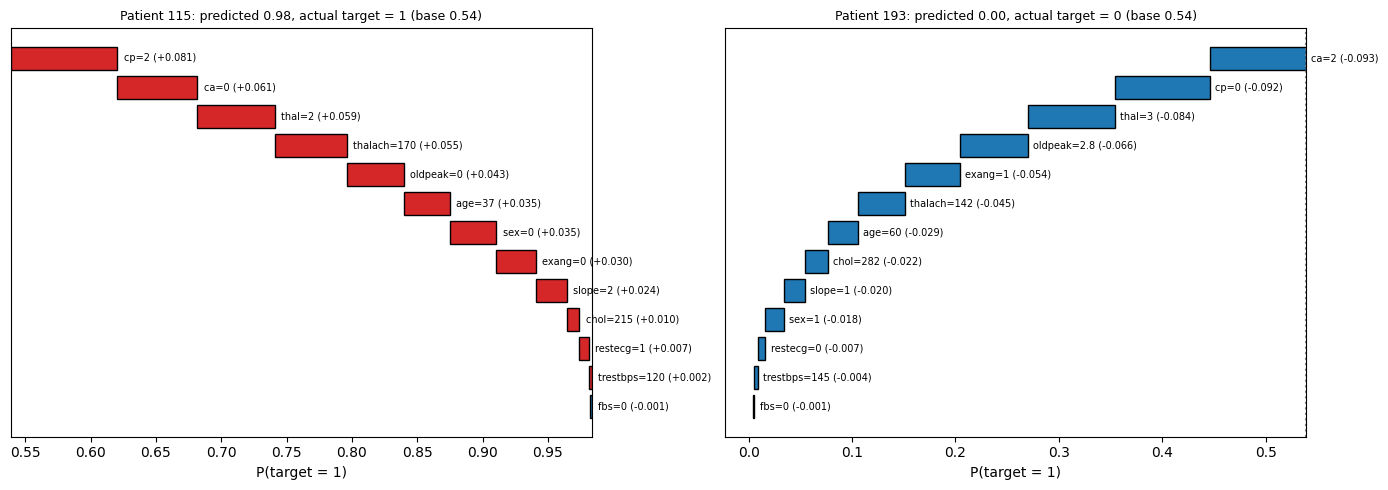

In [5]:
def waterfall(ax, x, phi, title):
    order = np.argsort(-np.abs(phi)); start = base; ypos = np.arange(n)[::-1]
    for r, j in enumerate(order):
        ax.barh(ypos[r], phi[j], left=start, color='tab:red' if phi[j] > 0 else 'tab:blue', edgecolor='k')
        ax.text(max(start, start + phi[j]) + 0.005, ypos[r], f'{feat[j]}={x[j]:g} ({phi[j]:+.3f})', va='center', fontsize=7); start += phi[j]
    ax.axvline(base, color='gray', ls=':'); ax.set_yticks([]); ax.set_xlabel('P(target = 1)'); ax.set_title(title, fontsize=9)

hi, lo = te[np.argmax(f(X[te]))], te[np.argmin(f(X[te]))]                         
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, i in zip(axes, [hi, lo]):
    waterfall(ax, X[i], exact_shapley(f, X[i], bg), f'Patient {i}: predicted {f(X[i:i+1])[0]:.2f}, actual target = {y[i]} (base {base:.2f})')
plt.tight_layout(); plt.show()

In [6]:
S = np.array([exact_shapley(f, X[i], bg) for i in te])                             
print('Shapley matrix:', S.shape, '| efficiency check (max |base + sum(phi) - prediction|):', np.abs(base + S.sum(1) - f(X[te])).max())

Shapley matrix: (61, 13) | efficiency check (max |base + sum(phi) - prediction|): 1.1102230246251565e-16


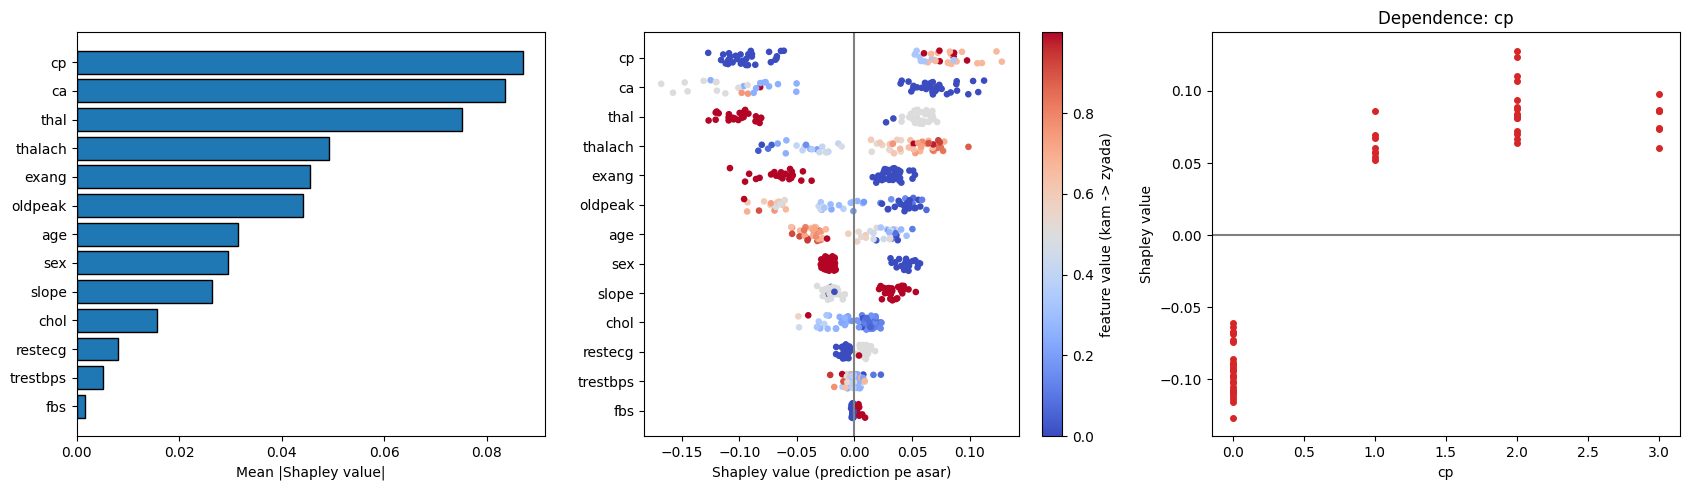

In [7]:
imp = np.abs(S).mean(0); order = np.argsort(imp)
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
axes[0].barh(range(n), imp[order], color='tab:blue', edgecolor='k'); axes[0].set_yticks(range(n)); axes[0].set_yticklabels([feat[j] for j in order]); axes[0].set_xlabel('Mean |Shapley value|')
rng = np.random.default_rng(0)
for r, j in enumerate(order):
    v = X[te][:, j]; c = (v - v.min()) / (np.ptp(v) + 1e-9)
    sc = axes[1].scatter(S[:, j], r + rng.uniform(-0.25, 0.25, len(te)), c=c, cmap='coolwarm', s=14)
axes[1].axvline(0, color='gray'); axes[1].set_yticks(range(n)); axes[1].set_yticklabels([feat[j] for j in order]); axes[1].set_xlabel('Shapley value (prediction pe asar)'); plt.colorbar(sc, ax=axes[1], label='feature value (kam -> zyada)')
top = order[-1]; axes[2].scatter(X[te][:, top], S[:, top], s=16, c='tab:red'); axes[2].axhline(0, color='gray'); axes[2].set_xlabel(feat[top]); axes[2].set_ylabel('Shapley value'); axes[2].set_title(f'Dependence: {feat[top]}')
plt.tight_layout(); plt.show()

In [8]:
rows = []
for j in np.argsort(-imp):
    s = S[:, j]
    rows.append((feat[j], f'{imp[j]:.3f}', f'{s.mean():+.3f}', f'{s.std():.3f}', f'{s.min():+.3f} to {s.max():+.3f}', f'{np.mean(s > 0.005):.0%} / {np.mean(s < -0.005):.0%}'))
pd.DataFrame(rows, columns=['Feature', 'Mean |phi|', 'Mean phi', 'Std phi', 'Range', 'Pushes up / down'])

,Feature,Mean |phi|,Mean phi,Std phi,Range,Pushes up / down
0,cp,0.087,-0.005,0.089,-0.127 to +0.128,51% / 49%
1,ca,0.084,-0.000,0.088,-0.168 to +0.113,59% / 41%
2,thal,0.075,-0.010,0.078,-0.127 to +0.072,57% / 43%
3,thalach,0.049,+0.018,0.050,-0.083 to +0.099,66% / 34%
4,exang,0.046,-0.006,0.050,-0.108 to +0.053,61% / 39%
5,oldpeak,0.044,-0.002,0.050,-0.096 to +0.063,51% / 43%
6,age,0.031,-0.004,0.033,-0.055 to +0.050,48% / 49%
7,sex,0.029,-0.000,0.032,-0.029 to +0.057,33% / 67%
8,slope,0.026,+0.007,0.027,-0.032 to +0.053,51% / 49%
9,chol,0.016,+0.001,0.019,-0.049 to +0.023,57% / 34%


In [9]:
runs = np.array([perm_shapley(f, X[hi], bg, T=300, seed=s) for s in range(8)]); ex = exact_shapley(f, X[hi], bg)
print(f"{'Feature':10s} {'exact':>7s} {'approx mean':>12s} {'approx std':>11s}")
for j in np.argsort(-np.abs(ex))[:6]: print(f'{feat[j]:10s} {ex[j]:+7.3f} {runs[:, j].mean():+12.3f} {runs[:, j].std():11.4f}')
print('\nPatients ke beech std (top feature):', S[:, order[-1]].std().round(3), '| sampling noise std (same feature, ek patient):', runs[:, order[-1]].std().round(4))

Feature      exact  approx mean  approx std
cp          +0.081       +0.082      0.0029
ca          +0.061       +0.060      0.0021
thal        +0.059       +0.059      0.0006
thalach     +0.055       +0.055      0.0010
oldpeak     +0.043       +0.044      0.0013
age         +0.035       +0.034      0.0015

Patients ke beech std (top feature): 0.089 | sampling noise std (same feature, ek patient): 0.0029
